# Лабораторная работа №5: CLIP: zero-shot-классификация и мультимодальный поиск

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Сравнить prompt templates в zero-shot classification.
- Построить text-to-image retrieval.
- Дообучить projection head и оценить Recall@K.


## Теоретическая часть

CLIP обучает image encoder и text encoder в общем нормированном пространстве. Zero-shot logits пропорциональны cosine similarity между изображением и текстовыми шаблонами классов.

![CLIP](https://raw.githubusercontent.com/openai/CLIP/main/CLIP.png)


### Математическая постановка

$$s(x,t)=\frac{f_I(x)^\top f_T(t)}{\|f_I(x)\|\|f_T(t)\|},\qquad p(c\mid x)=\operatorname{softmax}(s(x,t_c)/\tau).$$
Для retrieval используются Recall@K и median rank.


### Материалы

- [OpenCLIP](https://github.com/mlfoundations/open_clip)
- [CLIP paper](https://arxiv.org/abs/2103.00020)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Сравнить prompt templates в zero-shot classification.
2. Построить text-to-image retrieval.
3. Дообучить projection head и оценить Recall@K.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** OpenCLIP ViT-B-32 frozen/малый projection head.
- **Ограничение данных:** CIFAR-10 или до 5 000 пар.
- **Fallback:** CPU на 500 объектах.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [1]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    # локально работаю на Apple Silicon, поэтому кроме CUDA проверяю MPS
    DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})

{'device': 'mps', 'fast_dev_run': False, 'data_root': '/Users/filipp/Desktop/рабочий стол/Вуз/учеба/computer_vision/computer_vision_2026/data'}


In [2]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Данные и предобученный CLIP

*Вес: 1 балл.*

**Постановка.** Индекс поиска и обучающие пары должны состоять из разных изображений.

Выполните следующие действия:
1. Загрузите CIFAR-10 train/test и OpenCLIP ViT-B-32.
2. Определите список классов и независимый test-загрузчик.

**Результат.** Объекты model, train_pairs, ds, classes, loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [3]:
import open_clip
import torchvision
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

CLIP_ARCH, CLIP_TAG = "ViT-B-32", "laion2b_s34b_b79k"
model, _, preprocess = open_clip.create_model_and_transforms(CLIP_ARCH, pretrained=CLIP_TAG, device=DEVICE)
model.eval()
tokenizer = open_clip.get_tokenizer(CLIP_ARCH)

raw_train = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, download=True)
classes = raw_train.classes
y_train_all = np.array(raw_train.targets)
N_PAIRS, N_VAL = (500, 200) if FAST_DEV_RUN else (5000, 1000)
pair_idx, rest = train_test_split(np.arange(len(y_train_all)), train_size=N_PAIRS, stratify=y_train_all, random_state=SEED)
val_idx, _ = train_test_split(rest, train_size=N_VAL, stratify=y_train_all[rest], random_state=SEED)
# пары «изображение — описание» строятся только из официального train; поисковый индекс — из test
train_pairs = [(int(i), f"a photo of a {classes[y_train_all[i]]}.") for i in pair_idx]

ds = torchvision.datasets.CIFAR10(DATA_ROOT, train=False, download=True, transform=preprocess)
if FAST_DEV_RUN:
    ds = Subset(ds, range(1000))
loader = DataLoader(ds, batch_size=256, shuffle=False)
train_view = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, transform=preprocess)
check(len(set(pair_idx) & set(val_idx)) == 0, "train-пары и validation не пересекаются")
print(f"OpenCLIP {CLIP_ARCH}/{CLIP_TAG}; train пар: {len(train_pairs)}, validation: {len(val_idx)}, test (индекс поиска): {len(ds)}")

✔ train-пары и validation не пересекаются
OpenCLIP ViT-B-32/laion2b_s34b_b79k; train пар: 5000, validation: 1000, test (индекс поиска): 10000


### Текстовые прототипы классов

*Вес: 1 балл.*

**Постановка.** Нормализация эмбеддингов превращает скалярное произведение в cosine similarity.

Выполните следующие действия:
1. Создайте несколько шаблонов класса.
2. Закодируйте и нормируйте текстовые прототипы.

**Результат.** templates и функция text_prototypes.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [4]:
templates = ["{}.", "a photo of a {}.", "a blurry photo of a {}.", "a low resolution photo of a {}.",
             "a photo of the small {}.", "an image showing a {}.", "a drawing of a {}."]

@torch.no_grad()
def encode_texts(texts):
    return F.normalize(model.encode_text(tokenizer(texts).to(DEVICE)).float(), dim=-1)

def text_prototypes(tpls):
    """Прототип класса — нормированное среднее эмбеддингов шаблонов (для одного шаблона — сам эмбеддинг)."""
    protos = torch.stack([encode_texts([t.format(c) for t in tpls]).mean(0) for c in classes])
    return F.normalize(protos, dim=-1)

P = text_prototypes(["a photo of a {}."])
check(tuple(P.shape) == (10, 512) and torch.allclose(P.norm(dim=-1), torch.ones(10, device=P.device), atol=1e-4),
      "прототипы нормированы: скалярное произведение = cosine similarity")

✔ прототипы нормированы: скалярное произведение = cosine similarity


### Zero-shot классификация

*Вес: 1 балл.*

**Постановка.** Подбор словесного шаблона влияет на прогноз без дополнительного обучения.

Выполните следующие действия:
1. Для каждого заранее заданного шаблона предскажите test-классы по сходству.
2. Зафиксируйте accuracy всех шаблонов без выбора лучшей модели по test.

**Результат.** zero_shot.json с фактической точностью шаблонов.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [5]:
@torch.no_grad()
def encode_images(data_loader):
    feats, labels = [], []
    for x, y in data_loader:
        feats.append(F.normalize(model.encode_image(x.to(DEVICE)).float(), dim=-1).cpu()); labels.append(y)
    return torch.cat(feats), torch.cat(labels)

t0 = time.time()
test_emb, test_labels = encode_images(loader)
val_emb, val_labels = encode_images(DataLoader(Subset(train_view, val_idx), batch_size=256))
enc_speed = (len(test_emb) + len(val_emb)) / (time.time() - t0)

def zs_accuracy(emb, labels, protos):
    return float(((emb.to(protos.device) @ protos.T).argmax(1).cpu() == labels).float().mean())

zero_shot = {"templates": {}, "n_test": len(test_emb)}
for t in templates:
    Pt = text_prototypes([t])
    zero_shot["templates"][t] = {"val_accuracy": zs_accuracy(val_emb, val_labels, Pt), "test_accuracy": zs_accuracy(test_emb, test_labels, Pt)}
P_ens = text_prototypes(templates)
zero_shot["ensemble"] = {"val_accuracy": zs_accuracy(val_emb, val_labels, P_ens), "test_accuracy": zs_accuracy(test_emb, test_labels, P_ens)}
# дальше использую вариант, выбранный по validation (часть train), а не по test
choices = {**{t: v["val_accuracy"] for t, v in zero_shot["templates"].items()}, "ensemble": zero_shot["ensemble"]["val_accuracy"]}
chosen = max(choices, key=choices.get)
zero_shot["chosen_on_validation"] = chosen
(ARTIFACTS / "zero_shot.json").write_text(json.dumps(zero_shot, indent=2))
for t, v in zero_shot["templates"].items():
    print(f"{t!r:38s} val={v['val_accuracy']:.4f} test={v['test_accuracy']:.4f}")
print(f"{'ensemble':38s} val={zero_shot['ensemble']['val_accuracy']:.4f} test={zero_shot['ensemble']['test_accuracy']:.4f}")
print("выбран по validation:", chosen, f"| кодирование {enc_speed:.0f} изобр./с")
PROTO_TEMPLATES = templates if chosen == "ensemble" else [chosen]

'{}.'                                  val=0.9220 test=0.9150
'a photo of a {}.'                     val=0.9440 test=0.9368
'a blurry photo of a {}.'              val=0.9350 test=0.9307
'a low resolution photo of a {}.'      val=0.9360 test=0.9311
'a photo of the small {}.'             val=0.9220 test=0.9190
'an image showing a {}.'               val=0.9440 test=0.9356
'a drawing of a {}.'                   val=0.9470 test=0.9370
ensemble                               val=0.9430 test=0.9349
выбран по validation: a drawing of a {}. | кодирование 526 изобр./с


### Векторный индекс изображений

*Вес: 1 балл.*

**Постановка.** Текстовый поиск опирается на сохранённые признаки реальных изображений.

Выполните следующие действия:
1. Извлеките нормированные эмбеддинги test и метки.
2. Вычислите top-10 для текстового запроса.

**Результат.** clip_index.pt и retrieval.json с индексами test.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [6]:
torch.save({"embeddings": test_emb.half(), "labels": test_labels, "model": f"{CLIP_ARCH}/{CLIP_TAG}", "split": "CIFAR-10 test"}, ARTIFACTS / "clip_index.pt")

def search(query, emb=test_emb, k=10, encode=encode_texts):
    q = encode([query])[0].cpu()
    scores = emb @ q
    top = torch.topk(scores, k)
    return top.indices.tolist(), top.values.tolist()

QUERY = "a photo of a dog."
idx, scores = search(QUERY)
(ARTIFACTS / "retrieval.json").write_text(json.dumps({"query": QUERY, "top10": [{"test_index": i, "score": s, "label": classes[int(test_labels[i])]}
                                                                                for i, s in zip(idx, scores)]}, indent=1))
print(QUERY, "→", [classes[int(test_labels[i])] for i in idx])

a photo of a dog. → ['dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog', 'dog']


### Релевантность поиска по классам

*Вес: 1 балл.*

**Постановка.** Precision@10 и recall@10 требуют фиксированного определения релевантности.

Выполните следующие действия:
1. Задайте релевантность как совпадение с классом запроса.
2. Вычислите метрики поиска для каждого класса.

**Результат.** retrieval_report.json с фактическими значениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [7]:
def retrieval_metrics(emb, labels, query_encoder, k=10):
    """Релевантен объект того же класса, что и запрос; запрос — текстовый шаблон класса."""
    rows = {}
    for c, name in enumerate(classes):
        q = query_encoder(c)
        order = torch.argsort(emb @ q, descending=True)
        rel = (labels[order] == c).float()
        n_rel = rel.sum()
        ap = float((torch.cumsum(rel, 0) / torch.arange(1, len(rel) + 1) * rel).sum() / n_rel)
        rows[name] = {"precision@10": float(rel[:k].mean()), "recall@10": float(rel[:k].sum() / n_rel),
                      "recall@100": float(rel[:100].sum() / n_rel), "AP": ap, "n_relevant": int(n_rel)}
    return rows

P_base = text_prototypes(PROTO_TEMPLATES)
base_report = retrieval_metrics(test_emb, test_labels, lambda c: P_base[c].cpu())
mean_p10 = float(np.mean([r["precision@10"] for r in base_report.values()]))
(ARTIFACTS / "retrieval_report.json").write_text(json.dumps({"relevance": "same class as query", "index_size": len(test_emb),
    "query_templates": PROTO_TEMPLATES, "per_class": base_report, "mean_precision@10": mean_p10,
    "mAP": float(np.mean([r["AP"] for r in base_report.values()]))}, indent=1))
import pandas as pd
print(pd.DataFrame(base_report).T.round(4).to_string()); print("mean precision@10:", mean_p10)

            precision@10  recall@10  recall@100      AP  n_relevant
airplane             1.0      0.010       0.100  0.9488      1000.0
automobile           0.8      0.008       0.090  0.8093      1000.0
bird                 1.0      0.010       0.097  0.7762      1000.0
cat                  1.0      0.010       0.095  0.8386      1000.0
deer                 1.0      0.010       0.100  0.9008      1000.0
dog                  0.7      0.007       0.077  0.6562      1000.0
frog                 1.0      0.010       0.100  0.9645      1000.0
horse                1.0      0.010       0.098  0.7995      1000.0
ship                 1.0      0.010       0.100  0.9023      1000.0
truck                1.0      0.010       0.100  0.9709      1000.0
mean precision@10: 0.95


### Данные для обучаемой проекции

*Вес: 1 балл.*

**Постановка.** Одинаковые подписи в мини-партии не являются отрицательными парами. Проекция обучается по классовым прототипам.

Выполните следующие действия:
1. Создайте две линейные проекции и инициализируйте тождественно.
2. Подготовьте независимые train-пары и optimizer.

**Результат.** image_head, text_head и train_loader.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [8]:
import torch.nn as nn
from torch.utils.data import TensorDataset

image_head = nn.Linear(512, 512, bias=False).to(DEVICE)
text_head = nn.Linear(512, 512, bias=False).to(DEVICE)
with torch.no_grad():
    image_head.weight.copy_(torch.eye(512)); text_head.weight.copy_(torch.eye(512))   # старт — исходный CLIP

pair_emb, pair_labels = encode_images(DataLoader(Subset(train_view, pair_idx), batch_size=256))
check(torch.equal(pair_labels, torch.from_numpy(y_train_all[pair_idx])), "эмбеддинги train-пар выровнены с их подписями")
# текстовые эмбеддинги всех шаблонов для всех классов: [10, n_templates, 512]
template_emb = torch.stack([encode_texts([t.format(c) for t in templates]) for c in classes])
train_loader = DataLoader(TensorDataset(pair_emb, pair_labels), batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(SEED))
optimizer = torch.optim.AdamW(list(image_head.parameters()) + list(text_head.parameters()), lr=1e-4, weight_decay=0.0)
logit_scale = model.logit_scale.exp().item()
print(f"train пар: {len(pair_emb)}, logit scale CLIP = {logit_scale:.1f}")

✔ эмбеддинги train-пар выровнены с их подписями
train пар: 5000, logit scale CLIP = 100.0


### Обучение проекций по меткам

*Вес: 1 балл.*

**Постановка.** Классовая cross-entropy не объявляет одинаковые captions взаимными негативами.

Выполните следующие действия:
1. Обучите проекции по logits изображения против всех десяти текстовых прототипов.
2. Сохраните обученные веса.

**Результат.** clip_projection.pt после оптимизации на train.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [9]:
def projected_prototypes():
    # прототип класса — нормированное среднее спроецированных шаблонов
    z = F.normalize(text_head(template_emb.to(DEVICE)), dim=-1).mean(1)
    return F.normalize(z, dim=-1)

EPOCHS = 2 if FAST_DEV_RUN else 30
hist = []
for epoch in range(EPOCHS):
    losses = []
    for x, y in train_loader:
        img = F.normalize(image_head(x.to(DEVICE)), dim=-1)
        logits = logit_scale * img @ projected_prototypes().T    # изображение против всех десяти классов
        loss = F.cross_entropy(logits, y.to(DEVICE))
        optimizer.zero_grad(); loss.backward(); optimizer.step(); losses.append(loss.item())
    hist.append(float(np.mean(losses)))
print("loss по эпохам:", [round(h, 4) for h in hist[::5]], "...", round(hist[-1], 4))
torch.save({"image_head": image_head.state_dict(), "text_head": text_head.state_dict(), "epochs": EPOCHS, "lr": 1e-4,
            "loss_history": hist, "train_pairs": len(pair_emb)}, ARTIFACTS / "clip_projection.pt")
check(hist[-1] < hist[0], "loss проекций уменьшился")

loss по эпохам: [0.1609, 0.05, 0.0259, 0.0143, 0.0078, 0.0038] ... 0.0026
✔ loss проекций уменьшился


### Оценка адаптированного поиска

*Вес: 1 балл.*

**Постановка.** После обучения все варианты сравниваются на одинаковых test-изображениях.

Выполните следующие действия:
1. Обновите test-эмбеддинги двумя проекциями.
2. Сравните accuracy и среднюю precision@10 до и после обучения.

**Результат.** adaptation.json с измеренными baseline и adapted значениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [10]:
with torch.no_grad():
    test_emb_ad = F.normalize(image_head(test_emb.to(DEVICE)), dim=-1).cpu()
    val_emb_ad = F.normalize(image_head(val_emb.to(DEVICE)), dim=-1).cpu()
    P_ad = projected_prototypes()
ad_report = retrieval_metrics(test_emb_ad, test_labels, lambda c: P_ad[c].cpu())
adaptation = {"baseline": {"test_accuracy": zs_accuracy(test_emb, test_labels, P_base), "val_accuracy": zs_accuracy(val_emb, val_labels, P_base),
                           "mean_precision@10": mean_p10, "mAP": float(np.mean([r["AP"] for r in base_report.values()]))},
              "adapted": {"test_accuracy": zs_accuracy(test_emb_ad, test_labels, P_ad), "val_accuracy": zs_accuracy(val_emb_ad, val_labels, P_ad),
                          "mean_precision@10": float(np.mean([r["precision@10"] for r in ad_report.values()])),
                          "mAP": float(np.mean([r["AP"] for r in ad_report.values()]))},
              "n_test": len(test_emb), "train_pairs": len(pair_emb)}
(ARTIFACTS / "adaptation.json").write_text(json.dumps(adaptation, indent=2))
print(pd.DataFrame(adaptation["baseline"], index=["baseline"]).T.join(pd.DataFrame(adaptation["adapted"], index=["adapted"]).T).round(4))

                   baseline  adapted
test_accuracy        0.9370   0.9569
val_accuracy         0.9470   0.9600
mean_precision@10    0.9500   1.0000
mAP                  0.8567   0.9687


### Лучшие и худшие результаты поиска

*Вес: 1 балл.*

**Постановка.** Конкретные ошибки поиска дополняют усреднённую precision@10.

Выполните следующие действия:
1. Выберите лучший и худший класс по precision@10.
2. Сохраните индексы и истинные классы найденных объектов.

**Результат.** search_examples.json с примерами реальных изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


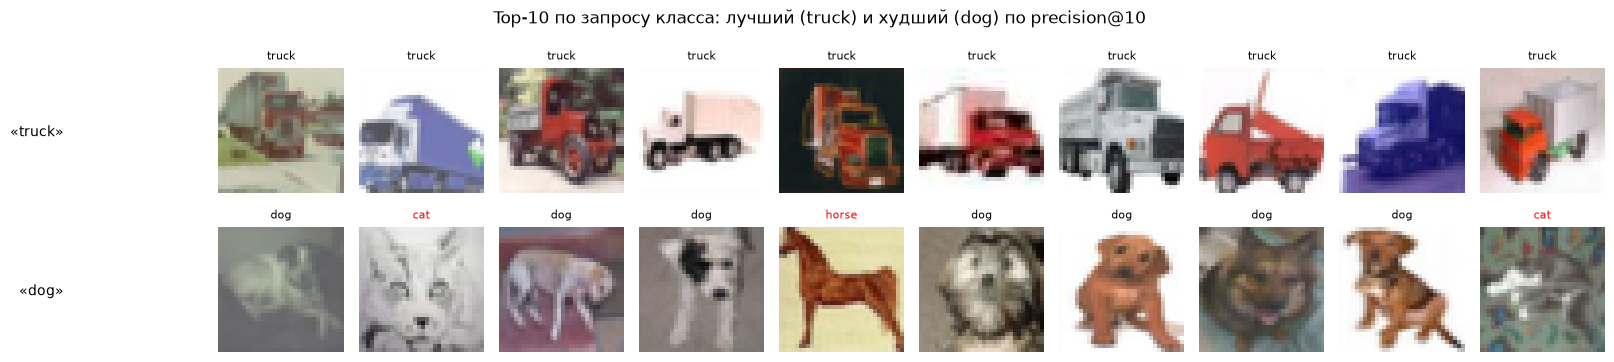

{'truck': 1.0, 'dog': 0.699999988079071}


In [11]:
import matplotlib.pyplot as plt
by_p10 = sorted(classes, key=lambda c: base_report[c]["precision@10"])
worst_c, best_c = by_p10[0], by_p10[-1]
examples = {}
for name in (best_c, worst_c):
    c = classes.index(name)
    idx = torch.topk(test_emb @ P_base[c].cpu(), 10).indices.tolist()
    examples[name] = {"precision@10": base_report[name]["precision@10"],
                      "results": [{"test_index": i, "true_class": classes[int(test_labels[i])]} for i in idx]}
(ARTIFACTS / "search_examples.json").write_text(json.dumps({"best_class": best_c, "worst_class": worst_c, "examples": examples}, indent=1))
raw_test = torchvision.datasets.CIFAR10(DATA_ROOT, train=False)
fig, axes = plt.subplots(2, 10, figsize=(16, 3.8))
for r, name in enumerate((best_c, worst_c)):
    for k, e in enumerate(examples[name]["results"]):
        ax = axes[r, k]; ax.imshow(raw_test.data[e["test_index"]]); ax.axis("off")
        ax.set_title(e["true_class"], fontsize=8, color="black" if e["true_class"] == name else "red")
    axes[r, 0].text(-40, 16, f"«{name}»", fontsize=10, ha="right", va="center")
fig.suptitle(f"Top-10 по запросу класса: лучший ({best_c}) и худший ({worst_c}) по precision@10"); fig.tight_layout()
fig.savefig(ARTIFACTS / "search_examples.png", dpi=100); plt.show()
print({n: examples[n]["precision@10"] for n in examples})

### Поклассовая динамика поиска

*Вес: 1 балл.*

**Постановка.** Средний показатель может скрывать ухудшение поиска для отдельных категорий.

Выполните следующие действия:
1. Повторно вычислите адаптированную precision@10 по каждому классу.
2. Сопоставьте её с исходной precision@10.

**Результат.** retrieval_deltas.json с наблюдаемыми поклассовыми изменениями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [12]:
deltas = {c: {"baseline_p@10": base_report[c]["precision@10"], "adapted_p@10": ad_report[c]["precision@10"],
              "delta_p@10": ad_report[c]["precision@10"] - base_report[c]["precision@10"],
              "baseline_AP": base_report[c]["AP"], "adapted_AP": ad_report[c]["AP"]} for c in classes}
(ARTIFACTS / "retrieval_deltas.json").write_text(json.dumps(deltas, indent=1))
print(pd.DataFrame(deltas).T.round(4).to_string())

            baseline_p@10  adapted_p@10  delta_p@10  baseline_AP  adapted_AP
airplane              1.0           1.0         0.0       0.9488      0.9795
automobile            0.8           1.0         0.2       0.8093      0.9913
bird                  1.0           1.0         0.0       0.7762      0.9455
cat                   1.0           1.0         0.0       0.8386      0.8872
deer                  1.0           1.0         0.0       0.9008      0.9743
dog                   0.7           1.0         0.3       0.6562      0.9447
frog                  1.0           1.0         0.0       0.9645      0.9865
horse                 1.0           1.0         0.0       0.7995      0.9906
ship                  1.0           1.0         0.0       0.9023      0.9922
truck                 1.0           1.0         0.0       0.9709      0.9956


### Творческий бонус: композиционный запрос

*Вес: 1 дополнительный балл.*

**Постановка.** Классовое имя не исчерпывает возможности текстово-визуального поиска.

Выполните следующие действия:
1. Сформулируйте собственный не-классовый запрос и получите top-10.
2. Сохраните коллаж найденных изображений для качественной оценки, не приписывая запросу искусственных меток.

**Результат.** bonus_retrieval.png и bonus_query.json с запросом и индексами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# Реализуйте это задание по постановке выше.
raise NotImplementedError("Реализуйте это задание в этой ячейке")


## Анализ результатов

Сопоставьте измеренные показатели на отложенных реальных данных. Укажите бюджет, ошибки модели и ограничения сокращённого запуска.


## Выводы

Сформулируйте предметный вывод по сохранённым артефактам.
